# Random Forest on Synthetic Emails


Dataset shape: (2374, 2)
Target distribution:
target
0    1187
1    1187
Name: count, dtype: int64

Train label distribution:
target
1    950
0    949
Name: count, dtype: int64

Test label distribution:
target
0    238
1    237
Name: count, dtype: int64

Random Forest Results
---------------------
Accuracy : 0.7810526315789473
Precision: 0.8275862068965517
Recall   : 0.7088607594936709
F1-score : 0.7636363636363637

Classification Report:
              precision    recall  f1-score   support

   Clean BEC       0.75      0.85      0.80       238
Poisoned BEC       0.83      0.71      0.76       237

    accuracy                           0.78       475
   macro avg       0.79      0.78      0.78       475
weighted avg       0.79      0.78      0.78       475



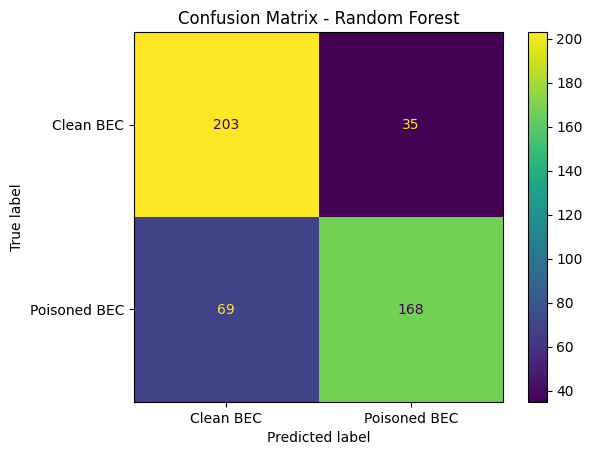

In [1]:
import pandas as pd, re, string
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS 
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

clean = pd.read_csv("synthetic_emails.csv")
poison = pd.read_csv("synthetic_emails_poisoned.csv")

# Xử lý missing values
clean = clean.drop_duplicates()
poison = poison.drop_duplicates()

clean = clean.dropna(subset=["label"])
poison = poison.dropna(subset=["label"])

clean["subject"] = clean["subject"].fillna("")
clean["body"] = clean["body"].fillna("")

poison["subject"] = poison["subject"].fillna("")
poison["body"] = poison["body"].fillna("")

# Ghép subject + body
clean["full_text"] = clean["subject"].astype(str) + " " + clean["body"].astype(str)
poison["full_text"] = poison["subject"].astype(str) + " " + poison["body"].astype(str)

# So sánh clean và poisoned bằng full_text
mask = clean["full_text"] != poison["full_text"]

clean_f = clean.loc[mask, ["full_text"]].copy()
poison_f = poison.loc[mask, ["full_text"]].copy()

# Tạo target mới
clean_f["target"] = 0
poison_f["target"] = 1

data = pd.concat([clean_f, poison_f], ignore_index=True)

print("Dataset shape:", data.shape)
print("Target distribution:")
print(data["target"].value_counts())

# Preprocessing
stops = set(ENGLISH_STOP_WORDS)

def prep(t):
    t = str(t).lower()
    t = re.sub(f"[{re.escape(string.punctuation)}]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return " ".join(w for w in t.split() if w not in stops)

data["text"] = data["full_text"].apply(prep)

# TF-IDF
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(data["text"])
y = data["target"]

# Train/test split
Xtr, Xte, ytr, yte = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
) 

print("\nTrain label distribution:")
print(ytr.value_counts())

print("\nTest label distribution:")
print(yte.value_counts())

# Random Forest
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(Xtr, ytr)
pred = rf.predict(Xte)

# Evaluation
print("\nRandom Forest Results")
print("---------------------")
print("Accuracy :", accuracy_score(yte, pred))
print("Precision:", precision_score(yte, pred))
print("Recall   :", recall_score(yte, pred))
print("F1-score :", f1_score(yte, pred))

print("\nClassification Report:")
print(classification_report(
    yte,
    pred,
    target_names=["Clean BEC", "Poisoned BEC"]
))

ConfusionMatrixDisplay.from_predictions(
    yte,
    pred,
    display_labels=["Clean BEC", "Poisoned BEC"]
)

plt.title("Confusion Matrix - Random Forest")
plt.show()